In [1]:
!pip install scikit-learn 

In [2]:
!pip install tensorflow

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from scipy.stats import pearsonr
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Conv1D, MaxPooling1D, Flatten, Dense, Dropout

# Load dataset
df = pd.read_csv("Bandwidth_synthetic_data_1.csv")

# Select features and target
features = ['RSSI', 'RSRQ', 'Speed', 'TA', 'LTE_Neighbour', 'Band', 'Echng']
target = 'Bandwidth'

# Drop missing values
df = df.dropna()

# Define X (features) and y (target)
X = df[features].values
y = df[target].values

# Normalize data (LSTM works better with normalized input)
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))

# Split into training, validation, and testing sets (60% train, 10% validation, 30% test)
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y_scaled, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.75, random_state=42)  # 30% test

# Reshape X for CNN-LSTM input (CNN-LSTM needs 3D input: [samples, timesteps, features])
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))  # (batch_size, time_steps, features)
X_val = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define TPA-LSTM model
model = Sequential()

# Add CNN layer
model.add(Conv1D(filters=64, kernel_size=1, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(MaxPooling1D(pool_size=1))

# Add LSTM layers
model.add(LSTM(32, return_sequences=True))
model.add(Dropout(0.2))

model.add(LSTM(32, return_sequences=False))
model.add(Dropout(0.2))

# Add Dense layer for prediction
model.add(Dense(1))  # Output layer for regression

# Compile model
model.compile(optimizer='adam', loss='mse')

# Train model
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val), verbose=1)

# Predictions
y_pred_scaled = model.predict(X_test)

# Convert predictions back to original scale
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_actual = scaler_y.inverse_transform(y_test)

# Evaluate model performance
mse = mean_squared_error(y_test_actual, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_actual, y_pred)
r2 = r2_score(y_test_actual, y_pred)
pearson_corr, _ = pearsonr(y_test_actual.flatten(), y_pred.flatten())


# Print performance metrics
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Correlation Coefficient (R²): {r2:.4f}")
print(f"Pearson Correlation Coefficient: {pearson_corr:.4f}")




C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 109s 5ms/step - loss: 0.0080 - val_loss: 0.0055
Epoch 2/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 107s 5ms/step - loss: 0.0057 - val_loss: 0.0056
Epoch 3/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 108s 5ms/step - loss: 0.0057 - val_loss: 0.0054
Epoch 4/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 106s 5ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 5/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 107s 5ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 6/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 107s 5ms/step - loss: 0.0056 - val_loss: 0.0054
Epoch 7/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 109s 5ms/step - loss: 0.0056 - val_loss: 0.0054
Epoch 8/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 107s 5ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 9/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 107s 5ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 10/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 106s 5ms/step - loss: 0.0056 - val_loss: 0.0054
Epoch 11/20
20250/20250 ━━━━━━━━━━━━━━━━━━━━ 105s 5ms/step - loss: 0.0056 - val

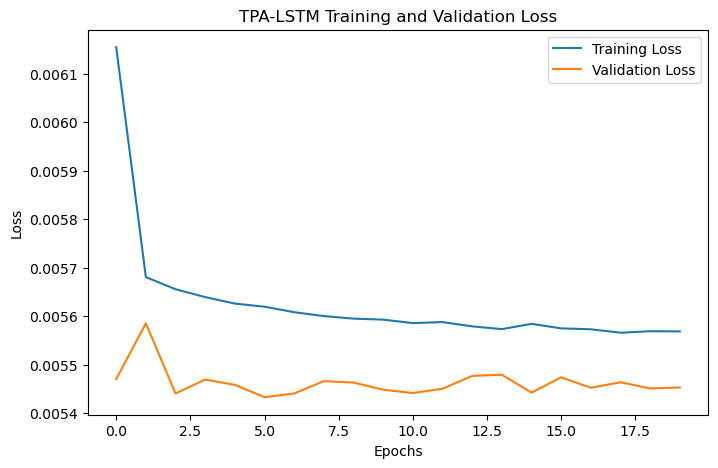

In [4]:
# Plot training & validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("TPA-LSTM Training and Validation Loss")
plt.legend()
plt.show()